In [1]:
import os

# Correct syntax
for j in ["train","val","test"]:
    if os.path.exists(f"/kaggle/input/datasets/aditya000001/group-16/Group_16/{j}"):
        print(f"The {j} exists!")

The train exists!
The val exists!
The test exists!


In [4]:
import numpy as np
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)

In [5]:
TARGET_SIZES = [32, 64, 128, 256]

In [6]:
ARCHITECTURES = {
    "3_hidden_best": [128, 64, 32],
    "4_hidden_best": [128, 64, 32, 16],
    "4_hidden_normal": [256, 128, 64, 32],
    "5_hidden_best": [256, 128, 64, 32, 16],
}

# **IMAGE DATA LOADING**

In [7]:
import os
from PIL import Image

def load_dataset(base_path):
    """
    Loads images from a structured folder (e.g., 'train') where subfolders are class names.
    Returns:
        X: NumPy array of images
        y: NumPy array of labels (integer indices)
        class_names: List of class names corresponding to indices
    """
    # 1. Get and sort the class names from the subdirectory names
    class_names = sorted(os.listdir(base_path))
    # Create a mapping from class name string to an integer label
    class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}
    
    images = []
    labels = []
    
    # 2. Iterate through each class folder
    for class_name in class_names:
        class_dir = os.path.join(base_path, class_name)
        
        # Skip if it's a file instead of a directory
        if not os.path.isdir(class_dir):
            continue
            
        # 3. Read every image in the class folder
        for img_name in os.listdir(class_dir):
            img_path = os.path.join(class_dir, img_name)
            
            try:
                # Open image using PIL
                with Image.open(img_path) as img:
                    # Optional: Resize images so they all have the same dimensions
                    # img = img.resize((128, 128)) 
                    
                    # # Optional: Convert to RGB if you have a mix of grayscale and CMYK
                    # img = img.convert('L')
                    
                    # Convert PIL image to a NumPy array
                    img_array = np.array(img)
                    
                    images.append(img_array)
                    labels.append(class_to_idx[class_name])
            except Exception as e:
                # Skip broken images or non-image files (like .DS_Store)
                print(f"Skipping {img_path}: {e}")
                
    # 4. Convert lists to final NumPy arrays
    X = np.array(images)
    y = np.array(labels)
    
    return X, y, class_names

# --- How to use it for your folders ---

# Define the root path where your train, val, and test folders live
dataset_root = "/kaggle/input/datasets/aditya000001/group-16/Group_16" 

# Load each split
X_train, y_train, classes = load_dataset(os.path.join(dataset_root, 'train'))
X_val, y_val, _          = load_dataset(os.path.join(dataset_root, 'val'))
X_test, y_test, _        = load_dataset(os.path.join(dataset_root, 'test'))

print(f"Train shapes: X={X_train.shape}, y={y_train.shape}")
print(f"Class labels mapping: {classes}")


Train shapes: X=(11385, 28, 28), y=(11385,)
Class labels mapping: ['1', '5', '6', '7', '9']


# **Normalizing data**

In [8]:
X_train_scaled = X_train/255.0
X_test_scaled = X_test/255.0
X_val_scaled = X_val / 255.0

# **Flattening**

In [9]:
X_train_flattened = X_train_scaled.reshape(X_train_scaled.shape[0], -1)
X_test_flattened = X_test_scaled.reshape(X_test_scaled.shape[0], -1)
X_val_flattened = X_val_scaled.reshape(X_val_scaled.shape[0], -1)
print("Shapes")
print(f"Train shapes: X={X_train_flattened.shape}")
print(f"Test shapes: X={X_test_flattened.shape}")
print(f"Val shapes: X={X_val_flattened.shape}")

Shapes
Train shapes: X=(11385, 784)
Test shapes: X=(3795, 784)
Val shapes: X=(3795, 784)


# **Centering** 

In [10]:
train_mean = np.mean(X_train_flattened, axis=0)
X_train_centered = X_train_flattened - train_mean
X_test_centered = X_test_flattened - train_mean
X_val_centered = X_val_flattened - train_mean

print("Shapes")
print(f"Train shapes: X={X_train_centered.shape}")
print(f"Test shapes: X={X_test_centered.shape}")
print(f"Val shapes: X={X_val_centered.shape}")

Shapes
Train shapes: X=(11385, 784)
Test shapes: X=(3795, 784)
Val shapes: X=(3795, 784)


In [11]:
print(np.max(np.abs(X_train_centered.mean(axis=0))))

2.3076168409888e-14


In [39]:
print("Train mean absolute mean:",
      np.mean(np.abs(X_train_centered.mean(axis=0))))

print("Validation centered using training mean:",
      np.mean(np.abs(X_val_centered.mean(axis=0))))

print("Test centered using training mean:",
      np.mean(np.abs(X_test_centered.mean(axis=0))))

Train mean absolute mean: 2.0946650466710396e-15
Validation centered using training mean: 0.0026724699541656686
Test centered using training mean: 0.002046228680317569


# **PCA**

In [41]:
from sklearn.decomposition import PCA

# Dictionaries to store the reduced datasets
reduced_train = {}
reduced_val = {}
reduced_test = {}
pca_models={}
for n in TARGET_SIZES:

    pca = PCA(
        n_components=n,
        random_state=RANDOM_STATE
    )

    reduced_train[n] = pca.fit_transform(
        X_train_centered
    )

    reduced_val[n] = pca.transform(
        X_val_centered
    )

    reduced_test[n] = pca.transform(
        X_test_centered
    )

    pca_models[n] = pca
    
    # Optional: Print verified shapes to confirm success
    print(f"--- Components: {n} ---")
    print(f"Train shape: {reduced_train[n].shape}")
    print(f"Val shape:   {reduced_val[n].shape}")
    print(f"Test shape:  {reduced_test[n].shape}")
    print(f"Explained Variance Ratio: {np.sum(pca.explained_variance_ratio_):.4f}\n")


--- Components: 32 ---
Train shape: (11385, 32)
Val shape:   (3795, 32)
Test shape:  (3795, 32)
Explained Variance Ratio: 0.7654

--- Components: 64 ---
Train shape: (11385, 64)
Val shape:   (3795, 64)
Test shape:  (3795, 64)
Explained Variance Ratio: 0.8708

--- Components: 128 ---
Train shape: (11385, 128)
Val shape:   (3795, 128)
Test shape:  (3795, 128)
Explained Variance Ratio: 0.9386

--- Components: 256 ---
Train shape: (11385, 256)
Val shape:   (3795, 256)
Test shape:  (3795, 256)
Explained Variance Ratio: 0.9807



In [42]:
import joblib

for n, pca in pca_models.items():

    joblib.dump(
        pca,
        os.path.join(
            CHECKPOINT_DIR,
            f"pca_{n}.joblib"
        )
    )

# **MODEL PART**

In [14]:
# ==========================================
# TASK 1 — FCNN CLASSIFICATION
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [15]:
ARCHITECTURES = {
    "3_hidden_best": [128, 64, 32],
    "4_hidden_best": [128, 64, 32, 16],
    "4_hidden_normal": [256, 128, 64, 32],
    "5_hidden_best": [256, 128, 64, 32, 16],
}

for name, layers in ARCHITECTURES.items():
    print(f"{name}: {layers}")

3_hidden_best: [128, 64, 32]
4_hidden_best: [128, 64, 32, 16]
4_hidden_normal: [256, 128, 64, 32]
5_hidden_best: [256, 128, 64, 32, 16]


In [16]:
class FCNN(nn.Module):

    def __init__(self, input_dim, hidden_layers, num_classes=5):
        super().__init__()

        layers = []

        prev_dim = input_dim

        # Hidden layers
        for hidden_dim in hidden_layers:

            linear = nn.Linear(prev_dim, hidden_dim)

            # Xavier initialization for tanh
            nn.init.xavier_uniform_(linear.weight)
            nn.init.zeros_(linear.bias)

            layers.append(linear)
            layers.append(nn.Tanh())

            prev_dim = hidden_dim

        # Output layer
        output = nn.Linear(prev_dim, num_classes)

        # Xavier initialization
        nn.init.xavier_uniform_(output.weight)
        nn.init.zeros_(output.bias)

        layers.append(output)

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [17]:
for pca_dim in [32, 64, 128, 256]:

    print(f"\nPCA dimension: {pca_dim}")

    for name, hidden_layers in ARCHITECTURES.items():

        model = FCNN(
            input_dim=pca_dim,
            hidden_layers=hidden_layers,
            num_classes=5
        )

        print(
            f"{name}: "
            f"input={pca_dim}, "
            f"hidden={hidden_layers}, "
            f"output=5"
        )


PCA dimension: 32
3_hidden_best: input=32, hidden=[128, 64, 32], output=5
4_hidden_best: input=32, hidden=[128, 64, 32, 16], output=5
4_hidden_normal: input=32, hidden=[256, 128, 64, 32], output=5
5_hidden_best: input=32, hidden=[256, 128, 64, 32, 16], output=5

PCA dimension: 64
3_hidden_best: input=64, hidden=[128, 64, 32], output=5
4_hidden_best: input=64, hidden=[128, 64, 32, 16], output=5
4_hidden_normal: input=64, hidden=[256, 128, 64, 32], output=5
5_hidden_best: input=64, hidden=[256, 128, 64, 32, 16], output=5

PCA dimension: 128
3_hidden_best: input=128, hidden=[128, 64, 32], output=5
4_hidden_best: input=128, hidden=[128, 64, 32, 16], output=5
4_hidden_normal: input=128, hidden=[256, 128, 64, 32], output=5
5_hidden_best: input=128, hidden=[256, 128, 64, 32, 16], output=5

PCA dimension: 256
3_hidden_best: input=256, hidden=[128, 64, 32], output=5
4_hidden_best: input=256, hidden=[128, 64, 32, 16], output=5
4_hidden_normal: input=256, hidden=[256, 128, 64, 32], output=5
5_hi

In [18]:
model = FCNN(
    input_dim=128,
    hidden_layers=[128, 64, 32, 16],
    num_classes=5
)

print(model)

FCNN(
  (network): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): Tanh()
    (8): Linear(in_features=16, out_features=5, bias=True)
  )
)


In [19]:
first_linear = model.network[0]

print("Weight shape:", first_linear.weight.shape)
print("Weight mean:", first_linear.weight.mean().item())
print("Weight std:", first_linear.weight.std().item())
print("Bias mean:", first_linear.bias.mean().item())

Weight shape: torch.Size([128, 128])
Weight mean: 0.000218958652112633
Weight std: 0.08816952258348465
Bias mean: 0.0


In [20]:
def numpy_to_tensor(X, y):
    X_tensor = torch.from_numpy(
        X.astype(np.float32)
    )

    y_tensor = torch.from_numpy(
        y.astype(np.int64)
    )

    return X_tensor, y_tensor

In [23]:
X_train_32, y_train_tensor = numpy_to_tensor(
    reduced_train[32],
    y_train
)

X_val_32, y_val_tensor = numpy_to_tensor(
    reduced_val[32],
    y_val
)

X_test_32, y_test_tensor = numpy_to_tensor(
    reduced_test[32],
    y_test
)

In [24]:
X_train_gpu = X_train_32.to(device)
y_train_gpu = y_train_tensor.to(device)

X_val_gpu = X_val_32.to(device)
y_val_gpu = y_val_tensor.to(device)

X_test_gpu = X_test_32.to(device)
y_test_gpu = y_test_tensor.to(device)

In [26]:
BATCH_SIZE = 1

In [27]:
def iterate_minibatches(X, y, batch_size=1, shuffle=True):

    n_samples = X.shape[0]

    if shuffle:
        indices = torch.randperm(n_samples, device=X.device)
    else:
        indices = torch.arange(n_samples, device=X.device)

    for start in range(0, n_samples, batch_size):

        batch_indices = indices[start:start + batch_size]

        yield X[batch_indices], y[batch_indices]

In [45]:
def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    max_epochs=100,
    batch_size=1,
    learning_rate=0.001,
    momentum=0.9,
    convergence_threshold=1e-4,
    warmup_epochs=2
):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=momentum
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_accuracy = -1.0
    best_epoch = 0
    best_state_dict = None

    previous_train_loss = None

    for epoch in range(max_epochs):

        # ==========================================
        # TRAINING
        # ==========================================

        model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for X_batch, y_batch in iterate_minibatches(
            X_train,
            y_train,
            batch_size=batch_size,
            shuffle=True
        ):

            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * X_batch.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == y_batch).sum().item()

            total += y_batch.size(0)

        # Average training loss
        train_loss = total_loss / total

        train_accuracy = (
            100.0 * correct / total
        )

        # ==========================================
        # VALIDATION
        # ==========================================

        model.eval()

        with torch.no_grad():

            val_outputs = model(X_val)

            val_predictions = torch.argmax(
                val_outputs,
                dim=1
            )

            val_accuracy = (
                100.0
                * (val_predictions == y_val).sum().item()
                / y_val.size(0)
            )

        # ==========================================
        # SAVE HISTORY
        # ==========================================

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        # ==========================================
        # SAVE BEST VALIDATION MODEL
        # ==========================================

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_epoch = epoch + 1

            best_state_dict = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        # ==========================================
        # CONVERGENCE CHECK
        # ==========================================

        loss_difference = None

        if previous_train_loss is not None:

            loss_difference = abs(
                train_loss - previous_train_loss
            )

        print(
            f"Epoch [{epoch + 1:3d}/{max_epochs}] "
            f"Loss: {train_loss:.6f} "
            f"Train Acc: {train_accuracy:.4f}% "
            f"Val Acc: {val_accuracy:.4f}%"
            + (
                f" | ΔLoss: {loss_difference:.6f}"
                if loss_difference is not None
                else ""
            )
        )

        # ------------------------------------------
        # A3 CONVERGENCE RULE
        #
        # Do NOT check during first 2 epochs.
        # ------------------------------------------

        if (
            epoch + 1 > warmup_epochs
            and loss_difference is not None
            and loss_difference < convergence_threshold
        ):

            print(
                f"\nConverged at epoch {epoch + 1}"
                f" | ΔLoss = {loss_difference:.8f}"
                f" < {convergence_threshold}"
            )

            break

        previous_train_loss = train_loss

    # ==========================================
    # RESTORE BEST VALIDATION MODEL
    # ==========================================

    model.load_state_dict(best_state_dict)

    print(
        f"\nBest validation accuracy: "
        f"{best_val_accuracy:.4f}% "
        f"(Epoch {best_epoch})"
    )

    return (
        model,
        optimizer,
        history,
        best_val_accuracy,
        best_epoch
    )

In [29]:
model = FCNN(
    input_dim=32,
    hidden_layers=[128, 64, 32, 16],
    num_classes=5
)

X_train_gpu = torch.from_numpy(
    reduced_train[32].astype(np.float32)
).to(device)

X_val_gpu = torch.from_numpy(
    reduced_val[32].astype(np.float32)
).to(device)

y_train_gpu = torch.from_numpy(
    y_train.astype(np.int64)
).to(device)

y_val_gpu = torch.from_numpy(
    y_val.astype(np.int64)
).to(device)

In [33]:
model, history, best_val_accuracy, best_epoch = train_model(
    model,
    X_train_gpu,
    y_train_gpu,
    X_val_gpu,
    y_val_gpu,
    epochs=5,
    batch_size=1,
    learning_rate=0.001,
    momentum=0.9
)

Epoch [  1/5] Loss: 0.012825 Train Acc: 99.5169% Val Acc: 98.4190%
Epoch [  2/5] Loss: 0.018717 Train Acc: 99.4466% Val Acc: 98.2082%
Epoch [  3/5] Loss: 0.008864 Train Acc: 99.7101% Val Acc: 98.4980%
Epoch [  4/5] Loss: 0.004474 Train Acc: 99.8946% Val Acc: 98.6034%
Epoch [  5/5] Loss: 0.001811 Train Acc: 99.9736% Val Acc: 98.6825%

Best validation accuracy: 98.6825% (Epoch 5)


In [35]:
import os

CHECKPOINT_DIR = "/kaggle/working/task1_checkpoints"

if os.path.exists("/kaggle/working"):
    CHECKPOINT_DIR = "/kaggle/working/task1_checkpoints"
else:
    CHECKPOINT_DIR = "/content/task1_checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Checkpoint directory:", CHECKPOINT_DIR)

Checkpoint directory: /kaggle/working/task1_checkpoints


In [36]:
def save_checkpoint(
    model,
    optimizer,
    history,
    pca_dim,
    architecture_name,
    hidden_layers,
    best_val_accuracy,
    best_epoch
):

    filename = (
        f"pca_{pca_dim}_"
        f"{architecture_name}_"
        f"best.pt"
    )

    filepath = os.path.join(
        CHECKPOINT_DIR,
        filename
    )

    checkpoint = {
        "pca_dim": pca_dim,
        "architecture_name": architecture_name,
        "hidden_layers": hidden_layers,
        "input_dim": pca_dim,
        "num_classes": 5,

        "best_val_accuracy": best_val_accuracy,
        "best_epoch": best_epoch,

        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        "history": history,

        "learning_rate": 0.001,
        "momentum": 0.9,
        "batch_size": 1,
        "activation": "tanh",
        "initialization": "xavier_uniform",
        "seed": 42
    }

    torch.save(checkpoint, filepath)

    print(f"Saved checkpoint: {filepath}")

    return filepath

In [46]:
# ==========================================
# TASK 1 — RUN ALL 16 EXPERIMENTS
# ==========================================

all_results = []

for pca_dim in TARGET_SIZES:

    print("\n")
    print("=" * 70)
    print(f"                 PCA-{pca_dim}")
    print("=" * 70)

    # Convert PCA representation to tensors ONCE
    X_train_tensor = torch.from_numpy(
        reduced_train[pca_dim].astype(np.float32)
    ).to(device)

    X_val_tensor = torch.from_numpy(
        reduced_val[pca_dim].astype(np.float32)
    ).to(device)

    y_train_tensor = torch.from_numpy(
        y_train.astype(np.int64)
    ).to(device)

    y_val_tensor = torch.from_numpy(
        y_val.astype(np.int64)
    ).to(device)

    for architecture_name, hidden_layers in ARCHITECTURES.items():

        print("\n")
        print("-" * 70)
        print(f"PCA: {pca_dim}")
        print(f"Architecture: {architecture_name}")
        print(f"Hidden layers: {hidden_layers}")
        print("-" * 70)

        # Reproducibility
        torch.manual_seed(SEED)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        # Create model
        model = FCNN(
            input_dim=pca_dim,
            hidden_layers=hidden_layers,
            num_classes=5
        )

        # Train
        model, optimizer, history, best_val_accuracy, best_epoch = train_model(
            model,
            X_train_tensor,
            y_train_tensor,
            X_val_tensor,
            y_val_tensor,
            batch_size=BATCH_SIZE,
            learning_rate=0.001,
            momentum=0.9
        )

        # Save model immediately
        checkpoint_path = save_checkpoint(
            model=model,
            optimizer=optimizer,
            history=history,
            pca_dim=pca_dim,
            architecture_name=architecture_name,
            hidden_layers=hidden_layers,
            best_val_accuracy=best_val_accuracy,
            best_epoch=best_epoch
        )

        # Store result
        all_results.append({
            "pca_dim": pca_dim,
            "architecture": architecture_name,
            "hidden_layers": str(hidden_layers),
            "best_epoch": best_epoch,
            "best_val_accuracy": best_val_accuracy,
            "checkpoint": checkpoint_path
        })

        # Free model/GPU memory
        del model
        del optimizer

        torch.cuda.empty_cache()

        print(
            f"\nCompleted: PCA-{pca_dim} | "
            f"{architecture_name} | "
            f"Best Val = {best_val_accuracy:.4f}% | "
            f"Epoch = {best_epoch}"
        )



                 PCA-32


----------------------------------------------------------------------
PCA: 32
Architecture: 3_hidden_best
Hidden layers: [128, 64, 32]
----------------------------------------------------------------------
Epoch [  1/100] Loss: 0.169807 Train Acc: 94.7387% Val Acc: 96.8643%
Epoch [  2/100] Loss: 0.086065 Train Acc: 97.3913% Val Acc: 96.9960% | ΔLoss: 0.083742
Epoch [  3/100] Loss: 0.058106 Train Acc: 98.1730% Val Acc: 97.7339% | ΔLoss: 0.027959
Epoch [  4/100] Loss: 0.045139 Train Acc: 98.5507% Val Acc: 97.8920% | ΔLoss: 0.012967
Epoch [  5/100] Loss: 0.032857 Train Acc: 98.8845% Val Acc: 98.1818% | ΔLoss: 0.012282
Epoch [  6/100] Loss: 0.024130 Train Acc: 99.1919% Val Acc: 97.9183% | ΔLoss: 0.008727
Epoch [  7/100] Loss: 0.018598 Train Acc: 99.4906% Val Acc: 98.1555% | ΔLoss: 0.005532
Epoch [  8/100] Loss: 0.013192 Train Acc: 99.6047% Val Acc: 97.6812% | ΔLoss: 0.005406
Epoch [  9/100] Loss: 0.009216 Train Acc: 99.7716% Val Acc: 98.2872% | ΔLoss: 0.003977


In [47]:
import pandas as pd

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    ["pca_dim", "best_val_accuracy"],
    ascending=[True, False]
)

display(results_df)

,pca_dim,architecture,hidden_layers,best_epoch,best_val_accuracy,checkpoint
2,32,4_hidden_normal,"[256, 128, 64, 32]",13,98.682477,/kaggle/working/task1_checkpoints/pca_32_4_hid...
3,32,5_hidden_best,"[256, 128, 64, 32, 16]",14,98.629776,/kaggle/working/task1_checkpoints/pca_32_5_hid...
0,32,3_hidden_best,"[128, 64, 32]",12,98.498024,/kaggle/working/task1_checkpoints/pca_32_3_hid...
1,32,4_hidden_best,"[128, 64, 32, 16]",12,98.366271,/kaggle/working/task1_checkpoints/pca_32_4_hid...
7,64,5_hidden_best,"[256, 128, 64, 32, 16]",11,98.577075,/kaggle/working/task1_checkpoints/pca_64_5_hid...
4,64,3_hidden_best,"[128, 64, 32]",15,98.498024,/kaggle/working/task1_checkpoints/pca_64_3_hid...
6,64,4_hidden_normal,"[256, 128, 64, 32]",15,98.392622,/kaggle/working/task1_checkpoints/pca_64_4_hid...
5,64,4_hidden_best,"[128, 64, 32, 16]",15,98.287220,/kaggle/working/task1_checkpoints/pca_64_4_hid...
10,128,4_hidden_normal,"[256, 128, 64, 32]",15,98.418972,/kaggle/working/task1_checkpoints/pca_128_4_hi...
9,128,4_hidden_best,"[128, 64, 32, 16]",11,98.392622,/kaggle/working/task1_checkpoints/pca_128_4_hi...


In [48]:
RESULTS_DIR = os.path.join(
    CHECKPOINT_DIR,
    "results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

results_csv = os.path.join(
    RESULTS_DIR,
    "task1_validation_results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

print("Results saved to:", results_csv)

Results saved to: /kaggle/working/task1_checkpoints/results/task1_validation_results.csv


In [49]:
# ==========================================
# TASK 1 — LOAD SAVED CHECKPOINT
# ==========================================

def load_task1_checkpoint(
    pca_dim,
    architecture_name
):
    
    # Expected filename
    filename = (
        f"pca_{pca_dim}_"
        f"{architecture_name}_"
        f"best.pt"
    )

    # First try current checkpoint directory
    filepath = os.path.join(
        CHECKPOINT_DIR,
        filename
    )

    # If not found, try the original path stored in CSV
    if not os.path.exists(filepath):

        matching_rows = results_df[
            (results_df["pca_dim"] == pca_dim) &
            (results_df["architecture"] == architecture_name)
        ]

        if len(matching_rows) == 0:
            raise FileNotFoundError(
                f"No checkpoint entry found for "
                f"PCA-{pca_dim}, {architecture_name}"
            )

        filepath = matching_rows.iloc[0]["checkpoint"]

    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"Checkpoint not found:\n{filepath}\n\n"
            f"Make sure the downloaded .pt files are "
            f"in CHECKPOINT_DIR."
        )

    checkpoint = torch.load(
        filepath,
        map_location=device
    )

    model = FCNN(
        input_dim=checkpoint["input_dim"],
        hidden_layers=checkpoint["hidden_layers"],
        num_classes=checkpoint["num_classes"]
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(device)
    model.eval()

    print(f"Loaded checkpoint: {filepath}")
    print(
        f"PCA dimension      : {checkpoint['pca_dim']}"
    )
    print(
        f"Architecture       : {checkpoint['architecture_name']}"
    )
    print(
        f"Hidden layers      : {checkpoint['hidden_layers']}"
    )
    print(
        f"Best validation acc: "
        f"{checkpoint['best_val_accuracy']:.6f}%"
    )
    print(
        f"Best epoch         : "
        f"{checkpoint['best_epoch']}"
    )

    return model, checkpoint

In [50]:
# ==========================================
# TASK 1 — TEST EVALUATION FUNCTION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

def evaluate_on_test(
    model,
    X_test,
    y_test
):
    
    model.eval()

    with torch.no_grad():

        outputs = model(X_test)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

    y_true = y_test.cpu().numpy()
    y_pred = predictions.cpu().numpy()

    test_accuracy = (
        100.0 *
        accuracy_score(y_true, y_pred)
    )

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    return (
        test_accuracy,
        cm,
        y_true,
        y_pred
    )

In [51]:
# ==========================================
# TASK 1 — PREPARE TEST REPRESENTATIONS
# ==========================================

test_tensors = {}

for pca_dim in TARGET_SIZES:

    test_tensors[pca_dim] = torch.from_numpy(
        reduced_test[pca_dim].astype(np.float32)
    ).to(device)

y_test_tensor = torch.from_numpy(
    y_test.astype(np.int64)
).to(device)

print("Test representations prepared:")

for pca_dim, X_tensor in test_tensors.items():
    print(
        f"PCA-{pca_dim}: {X_tensor.shape}"
    )

print(
    "Labels:",
    y_test_tensor.shape
)

Test representations prepared:
PCA-32: torch.Size([3795, 32])
PCA-64: torch.Size([3795, 64])
PCA-128: torch.Size([3795, 128])
PCA-256: torch.Size([3795, 256])
Labels: torch.Size([3795])


In [52]:
# ==========================================
# TASK 1 — SELECT BEST ARCHITECTURE
# FOR EACH PCA DIMENSION
# ==========================================

best_models_per_pca = (
    results_df
    .sort_values(
        "best_val_accuracy",
        ascending=False
    )
    .groupby(
        "pca_dim",
        as_index=False
    )
    .first()
)

best_models_per_pca = best_models_per_pca.sort_values(
    "pca_dim"
)

display(
    best_models_per_pca[
        [
            "pca_dim",
            "architecture",
            "hidden_layers",
            "best_epoch",
            "best_val_accuracy"
        ]
    ]
)

,pca_dim,architecture,hidden_layers,best_epoch,best_val_accuracy
0,32,4_hidden_normal,"[256, 128, 64, 32]",13,98.682477
1,64,5_hidden_best,"[256, 128, 64, 32, 16]",11,98.577075
2,128,4_hidden_normal,"[256, 128, 64, 32]",15,98.418972
3,256,5_hidden_best,"[256, 128, 64, 32, 16]",17,98.445323


In [53]:
# ==========================================
# TASK 1 — TEST EVALUATION
# BEST MODEL FOR EACH PCA DIMENSION
# ==========================================

task1_test_results = []

confusion_matrices = {}

for _, row in best_models_per_pca.iterrows():

    pca_dim = int(row["pca_dim"])
    architecture_name = row["architecture"]

    print("\n")
    print("=" * 80)
    print(
        f"PCA-{pca_dim} | "
        f"{architecture_name}"
    )
    print("=" * 80)

    # Load saved best-validation checkpoint
    model, checkpoint = load_task1_checkpoint(
        pca_dim=pca_dim,
        architecture_name=architecture_name
    )

    # Test evaluation
    test_accuracy, cm, y_true, y_pred = evaluate_on_test(
        model,
        test_tensors[pca_dim],
        y_test_tensor
    )

    confusion_matrices[pca_dim] = cm

    print(
        f"\nValidation Accuracy: "
        f"{checkpoint['best_val_accuracy']:.6f}%"
    )

    print(
        f"Test Accuracy: "
        f"{test_accuracy:.6f}%"
    )

    print("\nConfusion Matrix:")
    print(cm)

    # Store result
    task1_test_results.append({

        "pca_dim": pca_dim,

        "architecture": architecture_name,

        "hidden_layers": row["hidden_layers"],

        "best_epoch": int(
            checkpoint["best_epoch"]
        ),

        "validation_accuracy": float(
            checkpoint["best_val_accuracy"]
        ),

        "test_accuracy": test_accuracy
    })

    # Free GPU memory
    del model
    torch.cuda.empty_cache()



PCA-32 | 4_hidden_normal
Loaded checkpoint: /kaggle/working/task1_checkpoints/pca_32_4_hidden_normal_best.pt
PCA dimension      : 32
Architecture       : 4_hidden_normal
Hidden layers      : [256, 128, 64, 32]
Best validation acc: 98.682477%
Best epoch         : 13

Validation Accuracy: 98.682477%
Test Accuracy: 98.050066%

Confusion Matrix:
[[750   3   2   4   0]
 [  0 744   9   0   6]
 [  1  10 747   1   0]
 [  4   0   4 737  14]
 [  1   5   1   9 743]]


PCA-64 | 5_hidden_best
Loaded checkpoint: /kaggle/working/task1_checkpoints/pca_64_5_hidden_best_best.pt
PCA dimension      : 64
Architecture       : 5_hidden_best
Hidden layers      : [256, 128, 64, 32, 16]
Best validation acc: 98.577075%
Best epoch         : 11

Validation Accuracy: 98.577075%
Test Accuracy: 98.234519%

Confusion Matrix:
[[751   4   1   2   1]
 [  0 745   9   0   5]
 [  1   9 747   1   1]
 [  2   2   3 744   8]
 [  3   6   0   9 741]]


PCA-128 | 4_hidden_normal
Loaded checkpoint: /kaggle/working/task1_checkpoin

In [54]:
# ==========================================
# TASK 1 — FINAL TEST RESULTS
# ==========================================

task1_test_results_df = pd.DataFrame(
    task1_test_results
)

task1_test_results_df = (
    task1_test_results_df
    .sort_values("pca_dim")
    .reset_index(drop=True)
)

display(
    task1_test_results_df
)

,pca_dim,architecture,hidden_layers,best_epoch,validation_accuracy,test_accuracy
0,32,4_hidden_normal,"[256, 128, 64, 32]",13,98.682477,98.050066
1,64,5_hidden_best,"[256, 128, 64, 32, 16]",11,98.577075,98.234519
2,128,4_hidden_normal,"[256, 128, 64, 32]",15,98.418972,98.234519
3,256,5_hidden_best,"[256, 128, 64, 32, 16]",17,98.445323,98.129117


In [55]:
# ==========================================
# TASK 1 — BEST PCA REPRESENTATION
# ==========================================

best_task1_row = task1_test_results_df.loc[
    task1_test_results_df["test_accuracy"].idxmax()
]

print("=" * 70)
print("BEST TASK 1 PCA REPRESENTATION")
print("=" * 70)

print(
    f"PCA Dimension : "
    f"{int(best_task1_row['pca_dim'])}"
)

print(
    f"Architecture  : "
    f"{best_task1_row['architecture']}"
)

print(
    f"Hidden Layers : "
    f"{best_task1_row['hidden_layers']}"
)

print(
    f"Validation Acc: "
    f"{best_task1_row['validation_accuracy']:.6f}%"
)

print(
    f"Test Accuracy : "
    f"{best_task1_row['test_accuracy']:.6f}%"
)

BEST TASK 1 PCA REPRESENTATION
PCA Dimension : 64
Architecture  : 5_hidden_best
Hidden Layers : [256, 128, 64, 32, 16]
Validation Acc: 98.577075%
Test Accuracy : 98.234519%


In [56]:
# ==========================================
# REUSABLE CONFUSION MATRIX PLOT
# ==========================================

import matplotlib.pyplot as plt

def plot_confusion_matrix(
    cm,
    class_names,
    title,
    save_path=None
):

    fig, ax = plt.subplots(
        figsize=(6, 5)
    )

    im = ax.imshow(cm)

    ax.set_xticks(
        np.arange(len(class_names))
    )

    ax.set_yticks(
        np.arange(len(class_names))
    )

    ax.set_xticklabels(class_names)
    ax.set_yticklabels(class_names)

    ax.set_xlabel(
        "Predicted Label"
    )

    ax.set_ylabel(
        "True Label"
    )

    ax.set_title(title)

    # Add numbers
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):

            ax.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.tight_layout()

    if save_path is not None:

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

        print(
            f"Saved: {save_path}"
        )

    plt.show()

In [57]:
# ==========================================
# TASK 1 FIGURES
# ==========================================

TASK1_FIG_DIR = os.path.join(
    CHECKPOINT_DIR,
    "figures"
)

os.makedirs(
    TASK1_FIG_DIR,
    exist_ok=True
)

Saved: /kaggle/working/task1_checkpoints/figures/confusion_matrix_pca_32.png


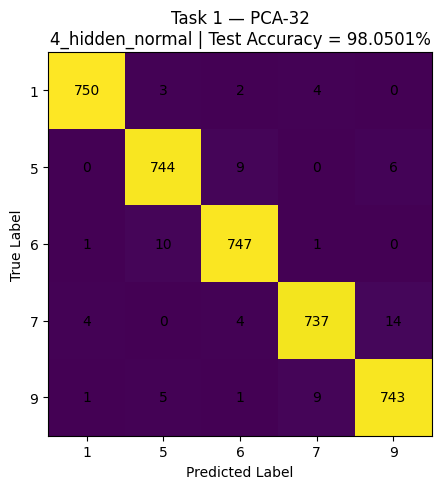

Saved: /kaggle/working/task1_checkpoints/figures/confusion_matrix_pca_64.png


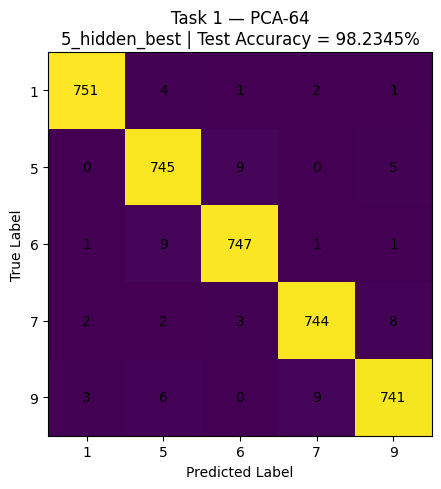

Saved: /kaggle/working/task1_checkpoints/figures/confusion_matrix_pca_128.png


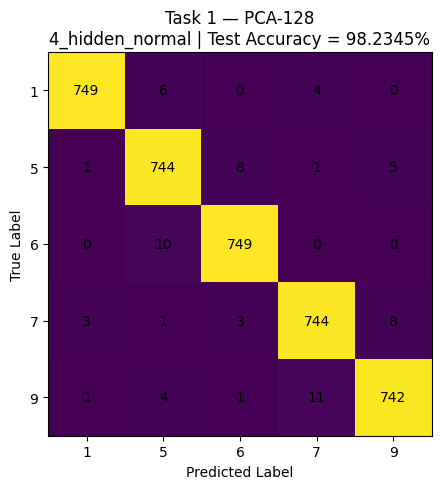

Saved: /kaggle/working/task1_checkpoints/figures/confusion_matrix_pca_256.png


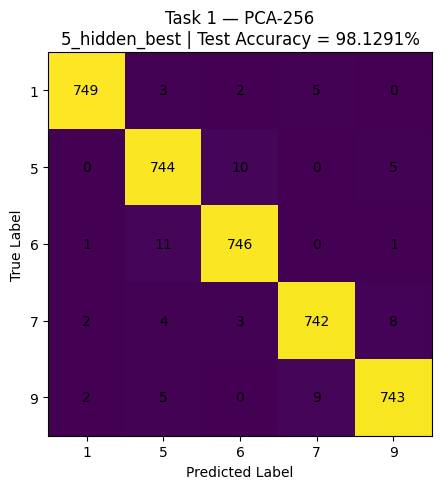

In [58]:
# ==========================================
# TASK 1 — ALL FOUR CONFUSION MATRICES
# ==========================================

for _, row in task1_test_results_df.iterrows():

    pca_dim = int(row["pca_dim"])

    architecture = row["architecture"]

    cm = confusion_matrices[pca_dim]

    save_path = os.path.join(
        TASK1_FIG_DIR,
        f"confusion_matrix_pca_{pca_dim}.png"
    )

    plot_confusion_matrix(
        cm=cm,
        class_names=classes,
        title=(
            f"Task 1 — PCA-{pca_dim}\n"
            f"{architecture} | "
            f"Test Accuracy = "
            f"{row['test_accuracy']:.4f}%"
        ),
        save_path=save_path
    )

In [59]:
# ==========================================
# SAVE TASK 1 TEST RESULTS
# ==========================================

task1_test_csv = os.path.join(
    RESULTS_DIR,
    "task1_test_results.csv"
)

task1_test_results_df.to_csv(
    task1_test_csv,
    index=False
)

print(
    "Task 1 test results saved to:"
)

print(task1_test_csv)

Task 1 test results saved to:
/kaggle/working/task1_checkpoints/results/task1_test_results.csv


In [60]:
# ==========================================
# SAVE CONFUSION MATRICES
# ==========================================

confusion_matrix_csv_dir = os.path.join(
    RESULTS_DIR,
    "confusion_matrices"
)

os.makedirs(
    confusion_matrix_csv_dir,
    exist_ok=True
)

for pca_dim, cm in confusion_matrices.items():

    filepath = os.path.join(
        confusion_matrix_csv_dir,
        f"confusion_matrix_pca_{pca_dim}.csv"
    )

    pd.DataFrame(
        cm,
        index=classes,
        columns=classes
    ).to_csv(filepath)

print(
    "Confusion matrices saved to:",
    confusion_matrix_csv_dir
)

Confusion matrices saved to: /kaggle/working/task1_checkpoints/results/confusion_matrices
